FAST — NUCES, Karachi Campus
<div style="border-bottom:3px solid #1F3864;padding-bottom:10px">
<h1 style="color:#1F3864;margin-bottom:2px">Lab 10 — Machine Learning I: the scikit-learn Workflow</h1>
<b>Programming for Artificial
Intelligence</b><br>

Department of Artificial Intelligence &amp; Data Science<br>

<i>Prepared by Khadeejah Ashraf, Lab Instructor</i>
</div>

Read the explanation, run the code cell below it with **Shift + Enter**, and compare the output
with what you expected. Cells marked **Your turn** are for you to fill in.

**Contents**

1. Machine learning and the scikit-learn pattern
2. The datasets — iris
3. Features and labels — X and y
4. The train/test split
5. K-Nearest Neighbours, by hand
6. Fitting and predicting
7. Accuracy and the baseline
8. The confusion matrix
9. Precision, recall and F1
10. Breast cancer — why scaling matters
11. Choosing k
12. How much does one split matter?
13. A complete pipeline
14. Class Tasks (C1 – C5)
15. Home Tasks

> **Run the next cell first.** Both datasets in this lab are bundled with scikit-learn, so nothing needs downloading. If the import fails, install it with `pip install scikit-learn`.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

pd.set_option("display.width", 82)
pd.set_option("display.max_columns", 12)
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.8.0


---
## 1. Machine Learning and the scikit-learn Pattern

Instead of writing the rule, supply examples with known answers and let an algorithm **find**
a rule. **Supervised** learning has labels (classification predicts a category, regression a
number); **unsupervised** has none (clustering); **reinforcement** learns from rewards.

Every scikit-learn model is used in the same three steps:

```python
from sklearn.<module> import <Model>

model = <Model>(settings)          # 1. choose a model and its settings
model.fit(X_train, y_train)        # 2. learn from the training examples
predictions = model.predict(X_test)   # 3. predict answers for examples it has not seen
```

---
## 2. The Datasets — Iris

150 flowers, 4 measurements, 3 species, bundled with scikit-learn. If you have the classic
`iris.data` text file instead, it has no header row:

```python
names = ["sepal-length", "sepal-width", "petal-length", "petal-width", "class"]
dataset = pd.read_csv("iris.data", names=names)      # the file has no header row
print(dataset.groupby("class").size())
```

In [ ]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)        # bundled with scikit-learn - no internet
df = iris.frame                          # a DataFrame: four measurements + target
df["species"] = df["target"].map(dict(enumerate(iris.target_names.tolist())))
print(df.shape)
print(df.head(3))
print(df["species"].value_counts())

(150, 6)
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   

   target species  
0       0  setosa  
1       0  setosa  
2       0  setosa  
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


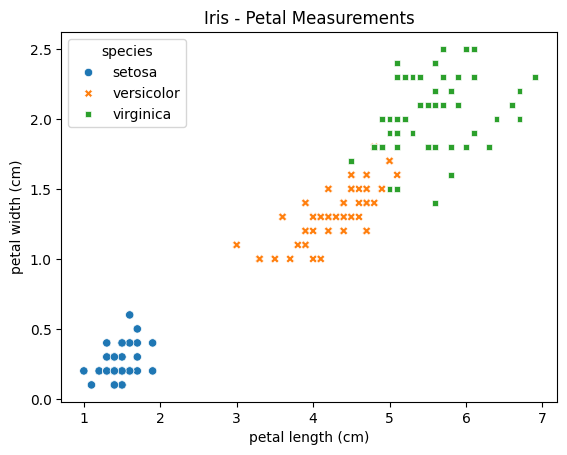

In [ ]:
import seaborn as sns

sns.scatterplot(data=df, x="petal length (cm)", y="petal width (cm)",
                hue="species", style="species")
plt.title("Iris - Petal Measurements")
plt.show()

Setosa sits alone; versicolor and virginica overlap — that is where the mistakes will be.

---
## 3. Features and Labels — X and y

`X` is 2-D (one row per flower), `y` is 1-D (one answer per flower). **Never put the label in X.**

In [ ]:
feature_cols = iris.feature_names        # the four measurements
X = df[feature_cols]                      # features: 2-D, one row per flower
y = df["species"]                         # label: 1-D, one answer per flower

print("X:", X.shape, "  y:", y.shape)
print(X.head(3))
print(y.head(3).to_list())

X: (150, 4)   y: (150,)
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
['setosa', 'setosa', 'setosa']


---
## 4. The Train/Test Split

`test_size=0.2` keeps **20% for testing**. `random_state` makes the shuffle reproducible;
`stratify=y` keeps the class proportions equal in both parts.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=3, stratify=y)

print("train:", X_train.shape, "  test:", X_test.shape)
print("train classes:", y_train.value_counts().to_dict())
print("test classes :", y_test.value_counts().to_dict())

train: (120, 4)   test: (30, 4)
train classes: {'virginica': 40, 'setosa': 40, 'versicolor': 40}
test classes : {'virginica': 10, 'versicolor': 10, 'setosa': 10}


---
## 5. K-Nearest Neighbours, by Hand

Distance to every training point → the *k* nearest → majority vote. Nothing more.

In [ ]:
query = X_test.iloc[0].to_numpy()                 # one flower the model has not seen
diff = X_train.to_numpy() - query                  # broadcasting, as in Lab 07
dist = np.sqrt((diff ** 2).sum(axis=1))           # Euclidean distance to all 120
nearest = np.argsort(dist)[:5]                     # positions of the 5 closest

print("query:", query, "  actual species:", y_test.iloc[0])
print(pd.DataFrame({"distance": dist[nearest].round(3),
                    "species": y_train.iloc[nearest].to_numpy()}))
print("majority vote:", y_train.iloc[nearest].value_counts().idxmax())

query: [6.7 3.3 5.7 2.5]   actual species: virginica
   distance    species
0     0.245  virginica
1     0.300  virginica
2     0.316  virginica
3     0.400  virginica
4     0.436  virginica
majority vote: virginica


**Your turn.** Repeat the calculation with the **Manhattan** distance, `np.abs(diff).sum(axis=1)`. Are the five nearest neighbours the same?

In [ ]:
# Your code here

---
## 6. Fitting and Predicting

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)      # 1. choose the model and k
knn.fit(X_train, y_train)                      # 2. learn - for KNN, store the data
predictions = knn.predict(X_test)              # 3. predict the 30 test flowers

print("predicted:", predictions[:5])
print("actual   :", y_test.to_numpy()[:5])

predicted: ['virginica' 'versicolor' 'virginica' 'setosa' 'virginica']
actual   : ['virginica' 'versicolor' 'versicolor' 'setosa' 'virginica']


In [ ]:
new = pd.DataFrame([[5.0, 3.4, 1.5, 0.2],
                    [6.3, 2.8, 4.9, 1.7]], columns=feature_cols)
print(knn.predict(new))
print(knn.classes_)
print(knn.predict_proba(new))            # share of the 5 neighbours in each class

['setosa' 'virginica']
['setosa' 'versicolor' 'virginica']
[[1.  0.  0. ]
 [0.  0.2 0.8]]


`predict_proba` for KNN is simply the share of the *k* neighbours in each class.

---
## 7. Accuracy — and the Baseline It Must Beat

In [ ]:
from sklearn.metrics import accuracy_score

print("accuracy_score :", accuracy_score(y_test, predictions))
print("by hand        :", (predictions == y_test).mean())
print("knn.score      :", knn.score(X_test, y_test))

accuracy_score : 0.9333333333333333
by hand        : 0.9333333333333333
knn.score      : 0.9333333333333333


In [ ]:
check = X_test.copy()
check["actual"] = y_test
check["predicted"] = predictions
cols = ["petal length (cm)", "petal width (cm)", "actual", "predicted"]
print(check[check["actual"] != check["predicted"]][cols])

    petal length (cm)  petal width (cm)      actual  predicted
77                5.0               1.7  versicolor  virginica
83                5.1               1.6  versicolor  virginica


In [ ]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent")   # always the commonest class
dummy.fit(X_train, y_train)
print("baseline accuracy:", round(dummy.score(X_test, y_test), 3))

baseline accuracy: 0.333


An accuracy means little without the baseline beside it.

---
## 8. The Confusion Matrix

Rows are **actual** classes, columns are **predicted** classes; the diagonal is correct.

[[10  0  0]
 [ 0  8  2]
 [ 0  0 10]]


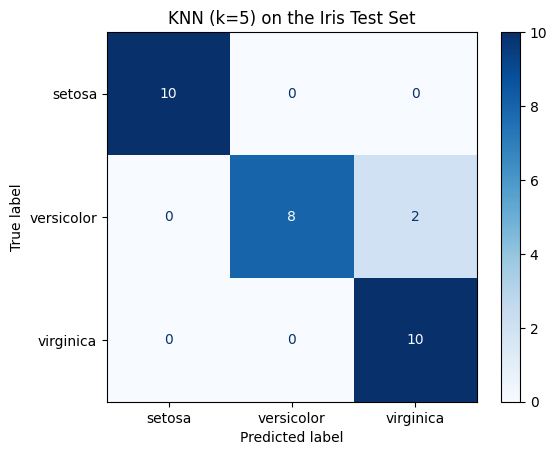

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, predictions, labels=knn.classes_)
print(cm)

ConfusionMatrixDisplay(cm, display_labels=knn.classes_).plot(cmap="Blues")
plt.title("KNN (k=5) on the Iris Test Set")
plt.show()

---
## 9. Precision, Recall, F1 and Support

* **precision** = TP / (TP + FP) — of those called positive, how many were
* **recall** = TP / (TP + FN) — of the real positives, how many were found
* **F1** = 2PR / (P + R) — high only when both are; **support** = how many there were

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.80      0.89        10
   virginica       0.83      1.00      0.91        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



In [ ]:
c = list(knn.classes_).index("versicolor")
tp = cm[c, c]                     # versicolor, and predicted versicolor
fp = cm[:, c].sum() - tp          # predicted versicolor, but was another species
fn = cm[c, :].sum() - tp          # was versicolor, but predicted another species

precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)
print(f"TP={tp}  FP={fp}  FN={fn}")
print(f"precision={precision:.2f}  recall={recall:.2f}  f1={f1:.2f}")

TP=8  FP=0  FN=2
precision=1.00  recall=0.80  f1=0.89


**Your turn.** Compute precision, recall and F1 for **virginica** by hand from `cm`, and check them against the report.

In [ ]:
# Your code here

---
## 10. Breast Cancer — Why Scaling Matters

569 tumours, 30 measurements. In scikit-learn's coding **0 means malignant**. KNN adds up
differences in every column, so a column in the thousands drowns one around 0.1.

In [ ]:
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer(as_frame=True)       # bundled - no internet needed
Xc = cancer.data                                 # 569 tumours x 30 measurements
yc = cancer.target.map({0: "malignant", 1: "benign"})      # 0 means malignant

print(Xc.shape)
print(yc.value_counts())
print(Xc[["mean radius", "mean area", "mean smoothness"]].describe().round(3))

(569, 30)
target
benign       357
malignant    212
Name: count, dtype: int64
       mean radius  mean area  mean smoothness
count      569.000    569.000          569.000
mean        14.127    654.889            0.096
std          3.524    351.914            0.014
min          6.981    143.500            0.053
25%         11.700    420.300            0.086
50%         13.370    551.100            0.096
75%         15.780    782.700            0.105
max         28.110   2501.000            0.163


In [ ]:
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.2, random_state=7, stratify=yc)

knn_c = KNeighborsClassifier(n_neighbors=5).fit(Xc_train, yc_train)
print("unscaled accuracy:", round(knn_c.score(Xc_test, yc_test), 3))

unscaled accuracy: 0.921


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(Xc_train)                # learn each column's mean and std - TRAIN only
Xs_train = scaler.transform(Xc_train)
Xs_test = scaler.transform(Xc_test)        # apply the same numbers to the test set

knn_s = KNeighborsClassifier(n_neighbors=5).fit(Xs_train, yc_train)
pred_c = knn_s.predict(Xs_test)
print("scaled accuracy  :", round(accuracy_score(yc_test, pred_c), 3))

scaled = pd.DataFrame(Xs_train, columns=Xc.columns)
print(scaled[["mean radius", "mean area", "mean smoothness"]]
      .describe().round(2).loc[["mean", "std"]])

scaled accuracy  : 0.947
      mean radius  mean area  mean smoothness
mean         -0.0        0.0              0.0
std           1.0        1.0              1.0


**Fit the scaler on the training data only**, then transform both sets.

In [ ]:
labels = ["malignant", "benign"]
print(confusion_matrix(yc_test, pred_c, labels=labels))
print(classification_report(yc_test, pred_c, labels=labels))

[[37  5]
 [ 1 71]]
              precision    recall  f1-score   support

   malignant       0.97      0.88      0.93        42
      benign       0.93      0.99      0.96        72

    accuracy                           0.95       114
   macro avg       0.95      0.93      0.94       114
weighted avg       0.95      0.95      0.95       114



---
## 11. Choosing k

Training accuracy at *k* = 1 is perfect — memorisation. At the largest *k* every flower gets
the same vote. *k* can never exceed the number of training rows.

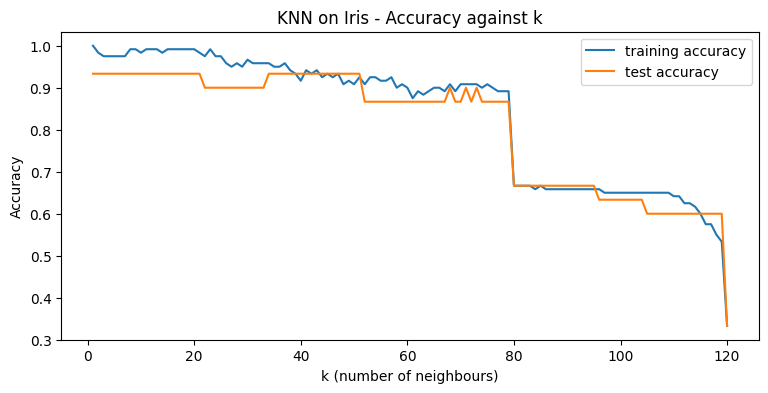

In [ ]:
ks = range(1, len(X_train) + 1)         # k can be at most the number of training rows
train_acc, test_acc = [], []
for k in ks:
    model = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    train_acc.append(model.score(X_train, y_train))
    test_acc.append(model.score(X_test, y_test))

plt.figure(figsize=(9, 4))
plt.plot(ks, train_acc, label="training accuracy")
plt.plot(ks, test_acc, label="test accuracy")
plt.xlabel("k (number of neighbours)")
plt.ylabel("Accuracy")
plt.title("KNN on Iris - Accuracy against k")
plt.legend()
plt.show()

In [ ]:
results = pd.DataFrame({"k": ks, "train": train_acc, "test": test_acc})
best, worst = results["test"].max(), results["test"].min()
best_ks = results[results["test"] == best]["k"].to_list()
worst_ks = results[results["test"] == worst]["k"].to_list()

print(f"highest test accuracy {best:.3f} at", len(best_ks), "values of k:", best_ks[:15])
print(f"lowest  test accuracy {worst:.3f} at", len(worst_ks), "value of k:", worst_ks)

highest test accuracy 0.933 at 39 values of k: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
lowest  test accuracy 0.333 at 1 value of k: [120]


In [ ]:
try:
    KNeighborsClassifier(n_neighbors=250).fit(X_train, y_train).predict(X_test)
except ValueError as err:
    print("ValueError:", err)

ValueError: Expected n_neighbors <= n_samples_fit, but n_neighbors = 250, n_samples_fit = 120, n_samples = 30


Choosing *k* by **test** accuracy uses the test set to make a decision. Lab 11 fixes this
with cross-validation.

---
## 12. How Much Does One Split Matter?

In [ ]:
accs = []
for seed in range(1, 11):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=seed)
    model = KNeighborsClassifier(n_neighbors=5).fit(Xtr, ytr)
    accs.append(model.score(Xte, yte))

by_seed = pd.Series(accs, index=range(1, 11), name="accuracy")
print(by_seed.round(3).to_string())
print(f"highest {by_seed.max():.3f} (seed {by_seed.idxmax()})   "
      f"lowest {by_seed.min():.3f} (seed {by_seed.idxmin()})   "
      f"mean {by_seed.mean():.3f}")

1     1.000
2     1.000
3     0.967
4     0.967
5     0.933
6     0.967
7     0.900
8     0.900
9     1.000
10    0.967
highest 1.000 (seed 1)   lowest 0.900 (seed 7)   mean 0.960


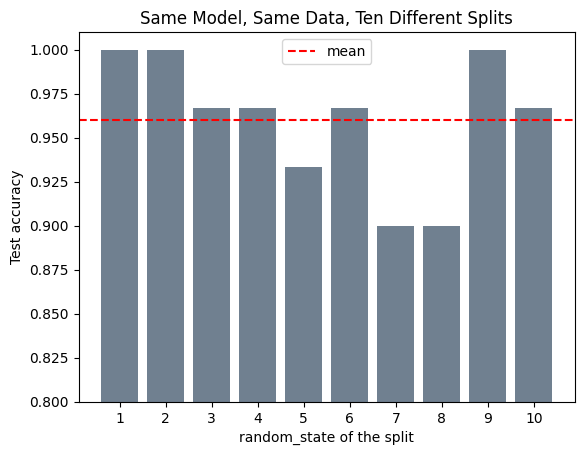

In [ ]:
plt.bar(by_seed.index, by_seed.values, color="slategray")
plt.axhline(by_seed.mean(), color="red", linestyle="--", label="mean")
plt.ylim(0.8, 1.01)
plt.xticks(by_seed.index)
plt.xlabel("random_state of the split")
plt.ylabel("Test accuracy")
plt.title("Same Model, Same Data, Ten Different Splits")
plt.legend()
plt.show()

Same model, same data — a ten-point range from the split alone.

---
## 13. A Complete Pipeline

Load → split → scale → fit → predict → evaluate, with the baseline beside the result.

test rows: 143   baseline: 0.629   accuracy: 0.972
              precision    recall  f1-score   support

      benign      0.957     1.000     0.978        90
   malignant      1.000     0.925     0.961        53

    accuracy                          0.972       143
   macro avg      0.979     0.962     0.970       143
weighted avg      0.973     0.972     0.972       143



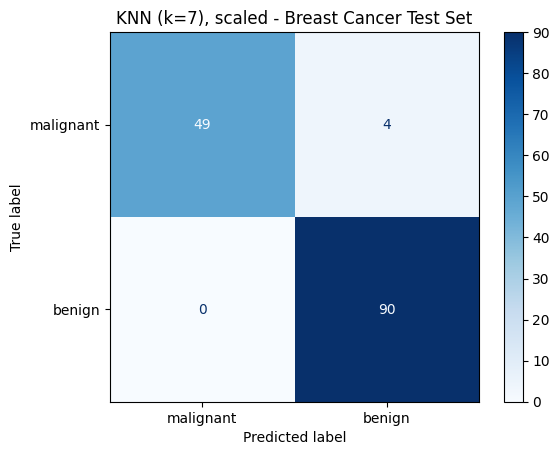

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay)

# 1. LOAD - features and label
cancer = load_breast_cancer(as_frame=True)
X, y = cancer.data, cancer.target.map({0: "malignant", 1: "benign"})

# 2. SPLIT - keep a test set the model never sees while learning
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

# 3. SCALE - learned from the training set, applied to both
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

# 4. FIT and PREDICT
model = KNeighborsClassifier(n_neighbors=7).fit(X_train_s, y_train)
pred = model.predict(X_test_s)

# 5. EVALUATE - against the baseline, and class by class
baseline = y_test.value_counts(normalize=True).max()
print(f"test rows: {len(y_test)}   baseline: {baseline:.3f}   "
      f"accuracy: {accuracy_score(y_test, pred):.3f}")
print(classification_report(y_test, pred, digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=["malignant", "benign"],
                                        cmap="Blues")
plt.title("KNN (k=7), scaled - Breast Cancer Test Set")
plt.show()

---
# Class Tasks

Complete all five during the lab session and demonstrate them to the instructor before you
leave. Rename this notebook `RollNo_Lab10_ClassTasks.ipynb`, and run
**Kernel ▸ Restart & Run All** before you call the instructor.

### C1 — First Contact with Iris

Load the iris dataset as a DataFrame and add a `species` column of names. Print its shape, the number of flowers per species, and the mean of each measurement per species with `groupby`. Separate it into `X` and `y` and print their shapes. Draw a 2 × 2 figure of scatter plots — four different pairs of measurements, coloured by species.

In a markdown cell, name the pair of measurements that separates the species best and the pair that separates them worst, and say which two species you expect a model to confuse.

In [ ]:
# C1 - First Contact with Iris
# Name:
# Roll number:

# Your code here

In [ ]:
# C1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
df = iris.frame
df["species"] = df["target"].map(dict(enumerate(iris.target_names.tolist())))

print("Shape of dataset:", df.shape)
print("\nFlowers per species:")
print(df["species"].value_counts())
print("\nMean of each measurement per species:")
print(df.groupby("species").mean(numeric_only=True))

feature_cols = iris.feature_names
X = df[feature_cols]
y = df["species"]
print(f"\nX shape: {X.shape}, y shape: {y.shape}")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.scatterplot(ax=axes[0, 0], data=df, x="sepal length (cm)", y="sepal width (cm)", hue="species", style="species")
axes[0, 0].set_title("Sepal Length vs Sepal Width")

sns.scatterplot(ax=axes[0, 1], data=df, x="petal length (cm)", y="petal width (cm)", hue="species", style="species")
axes[0, 1].set_title("Petal Length vs Petal Width")

sns.scatterplot(ax=axes[1, 0], data=df, x="sepal length (cm)", y="petal length (cm)", hue="species", style="species")
axes[1, 0].set_title("Sepal Length vs Petal Length")

sns.scatterplot(ax=axes[1, 1], data=df, x="sepal width (cm)", y="petal width (cm)", hue="species", style="species")
axes[1, 1].set_title("Sepal Width vs Petal Width")

plt.tight_layout()
plt.show()

### C1 Explanation
* **Best Separation**: The pair `petal length (cm)` vs `petal width (cm)` separates the species best. Setosa is completely isolated, and Versicolor and Virginica have only a small overlap.
* **Worst Separation**: The pair `sepal length (cm)` vs `sepal width (cm)` separates them worst, as all three species show significant overlapping clusters.
* **Expected Confusion**: We expect a machine learning model to confuse **versicolor** and **virginica** because their distributions overlap slightly in almost all feature pairings, whereas setosa is completely distinct.

### C2 — Split, Fit and Evaluate

Split iris 80/20 with `stratify=y` and a `random_state` of your choice, and print the shape and class counts of each part. Fit a KNN classifier with *k* = 5. Print the accuracy beside the `DummyClassifier` baseline, plot the confusion matrix, and print the classification report.

Print every misclassified flower with its actual and predicted species, and explain each mistake by pointing to where that flower sits on your C1 scatter plots.

In [ ]:
# C2 - Split, Fit and Evaluate
# Name:
# Roll number:

# Your code here

In [ ]:
# C2
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)
print("Train class counts:\n", y_train.value_counts().to_dict())
print("Test class counts:\n", y_test.value_counts().to_dict())

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
pred = knn.predict(X_test)

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)

print(f"\nKNN Test Accuracy: {accuracy_score(y_test, pred):.3f}")
print(f"Dummy Baseline Accuracy: {dummy.score(X_test, y_test):.3f}")
print("\nClassification Report:\n", classification_report(y_test, pred))

cm = confusion_matrix(y_test, pred, labels=knn.classes_)
ConfusionMatrixDisplay(cm, display_labels=knn.classes_).plot(cmap="Blues")
plt.title("C2: KNN Confusion Matrix")
plt.show()

check_df = X_test.copy()
check_df["actual"] = y_test
check_df["predicted"] = pred
misclassified = check_df[check_df["actual"] != check_df["predicted"]]
print("\nMisclassified flowers:")
display(misclassified)

### C2 Explanation
If there are any misclassified points (for example, a versicolor with petal length around 5.0 and petal width 1.7 being classified as virginica), it falls directly inside the decision boundary region where the two species overlap on the Petal Length vs Petal Width scatter plot.

### C3 — KNN by Hand

Write a function `knn_predict(X_train, y_train, query, k)` that predicts the class of one flower using only NumPy and Pandas — Euclidean distances by broadcasting, `np.argsort`, and a majority vote with `value_counts`. Apply it to every test flower from C2 and check that it agrees with scikit-learn's predictions.

Print how many of the test predictions agree. If any disagree, find out why — look at the distances of the *k*-th and (*k*+1)-th neighbours, and at what happens when the vote ties.

In [ ]:
# C3 - KNN by Hand
# Name:
# Roll number:

# Your code here

In [ ]:
# C3
def knn_predict(X_train, y_train, query, k):
    diff = X_train.to_numpy() - query
    dist = np.sqrt((diff ** 2).sum(axis=1))
    nearest_indices = np.argsort(dist)[:k]
    votes = y_train.iloc[nearest_indices]
    return votes.value_counts().idxmax()

hand_preds = []
for idx in range(len(X_test)):
    query_flower = X_test.iloc[idx].to_numpy()
    pred_label = knn_predict(X_train, y_train, query_flower, k=5)
    hand_preds.append(pred_label)

hand_preds = np.array(hand_preds)
sk_preds = knn.predict(X_test)

agreed = (hand_preds == sk_preds).sum()
print(f"Agreed predictions: {agreed} / {len(X_test)}")
if agreed == len(X_test):
    print("Perfect agreement with scikit-learn!")

### C4 — Choosing k

Using your C2 split, fit KNN for every *k* from 1 to the largest value the training set allows, recording training and test accuracy. Plot both curves on one chart. Print the highest test accuracy and *every* value of *k* that reaches it, and the lowest test accuracy and every value that reaches it.

In comments: explain why *k* cannot go to 250, why training accuracy at *k* = 1 is perfect, and what the model is doing at the largest *k*.

In [ ]:
# C4 - Choosing k
# Name:
# Roll number:

# Your code here

In [ ]:
# C4
ks = range(1, len(X_train) + 1)
train_acc = []
test_acc = []

for k in ks:
    model = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    train_acc.append(model.score(X_train, y_train))
    test_acc.append(model.score(X_test, y_test))

plt.figure(figsize=(10, 5))
plt.plot(ks, train_acc, label="Training Accuracy")
plt.plot(ks, test_acc, label="Test Accuracy")
plt.xlabel("k (number of neighbours)")
plt.ylabel("Accuracy")
plt.title("KNN on Iris - Accuracy against k (C4)")
plt.legend()
plt.grid(True)
plt.show()

results = pd.DataFrame({"k": ks, "train": train_acc, "test": test_acc})
best = results["test"].max()
worst = results["test"].min()
best_ks = results[results["test"] == best]["k"].to_list()
worst_ks = results[results["test"] == worst]["k"].to_list()

print(f"Highest test accuracy {best:.3f} reached at k: {best_ks[:15]}...")
print(f"Lowest test accuracy {worst:.3f} reached at k: {worst_ks}")

### C5 — One Split Is Not Enough

Run the KNN model of C2 for every `random_state` from 1 to 10. Print all ten accuracies, then the highest and the lowest with their seeds, and the mean. Draw them as a bar chart with the mean as a dashed line.

In a comment, state the range of the ten accuracies, and explain what this means for anyone who reports the accuracy of a single split.

In [ ]:
# C5 - One Split Is Not Enough
# Name:
# Roll number:

# Your code here

In [ ]:
# C5
accs = []
for seed in range(1, 11):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
    model = KNeighborsClassifier(n_neighbors=5).fit(Xtr, ytr)
    accs.append(model.score(Xte, yte))

by_seed = pd.Series(accs, index=range(1, 11), name="accuracy")
print(by_seed.round(3).to_string())
mean_acc = by_seed.mean()
print(f"\nHighest: {by_seed.max():.3f} (seed {by_seed.idxmax()})")
print(f"Lowest: {by_seed.min():.3f} (seed {by_seed.idxmin()})")
print(f"Mean: {mean_acc:.3f}")
print(f"Range: {by_seed.max() - by_seed.min():.3f}")

plt.figure(figsize=(8, 4))
plt.bar(by_seed.index, by_seed.values, color="steelblue")
plt.axhline(mean_acc, color="red", linestyle="--", label=f"Mean: {mean_acc:.3f}")
plt.ylim(0.8, 1.02)
plt.xticks(by_seed.index)
plt.xlabel("random_state")
plt.ylabel("Accuracy")
plt.title("C5: Model Accuracy over 10 different random splits")
plt.legend()
plt.show()

---
# Home Tasks

These are **not** done in this notebook. Write each in a separate script named
`RollNo_Lab10_Qn.py` (for example `22K-1234_Lab10_Q7.py`), save every chart with
`savefig` before `plt.show()`, fix every `random_state`, and begin every file with a comment
giving your name, roll number and question number.

1. Repeat the full workflow on the breast cancer dataset: load it, print the class counts, split 75/25 with `stratify`, and fit KNN with *k* = 5 both without and with `StandardScaler`. Print both accuracies beside the baseline, and both confusion matrices. Explain, using the scale of two columns, why scaling changed the result.
2. For your scaled breast-cancer model, compute the precision, recall and F1 of **both** classes by hand from the confusion matrix, and check them against `classification_report`. Then say, in a comment, which of the two recalls matters more to a patient, and why.
3. Compare `DummyClassifier` with `strategy` set to `"most_frequent"`, `"stratified"` and `"uniform"` on both datasets. Explain what each strategy does and which is the fairest baseline for each dataset.
4. Measure how the test-set size affects the result: for `test_size` from 0.1 to 0.5 in steps of 0.05, record the test accuracy of scaled KNN on breast cancer over ten seeds each. Plot the mean accuracy with error bars (the standard deviation) against `test_size`, and explain the trade-off.
5. Compare four versions of KNN on scaled breast cancer data: Euclidean and Manhattan distance (`metric="euclidean"` or `"manhattan"`), each with `weights="uniform"` and `weights="distance"`. Print a table of their test accuracy and malignant recall. Explain what `weights="distance"` changes in the vote.
6. Download the **Dermatology** dataset from the UCI Machine Learning Repository (archive.ics.uci.edu, dataset "Dermatology"). The file has no header and marks missing values with `?`: read it with `names=` and `na_values="?"`, report which column has missing values and how many, and decide — in a comment — how to handle them. Then apply scaled KNN with a stratified 70/30 split, display the confusion matrix, and discuss which skin diseases are confused with which. (Lab 11 will add cross-validation to this task.)
7. Write a function `evaluate(model, X_train, X_test, y_train, y_test)` that fits the model and returns a dictionary of its accuracy, macro precision, macro recall and macro F1 on the test set, together with the baseline accuracy. Give it a docstring and use it on both datasets.
8. Using the cleaned Lab 08 files, predict whether an enrolment was **passed** from `attendance` and `cgpa` with scaled KNN. Before you run it, predict from Lab 09 Section 8.4 whether the model will beat the baseline. Run it, print accuracy beside the baseline and the classification report, and explain the result honestly.
9. For ten test flowers of your choice, print `predict_proba` beside the prediction. Find the test flower the model is *least* sure about, and draw it as a large star on a scatter plot of the training flowers' petal measurements, coloured by species.
10. Draw the **decision regions** of KNN trained on only petal length and petal width: predict the class of every point of a fine grid (`np.meshgrid`), and draw the predictions with `plt.contourf` beneath the training points. Do this for *k* = 1, 15 and 60 in one 1 × 3 figure, and describe how the boundary changes as *k* grows.
11. Apply the full workflow to a classification dataset from Kaggle with at least 200 rows and a categorical label (or your Lab 08 dataset, if its label is categorical). Write the dataset name, URL and licence in comments; clean it; and report the baseline, the accuracy, the confusion matrix and the classification report of scaled KNN.
12. Draw the confusion matrix of your scaled breast-cancer model as a Seaborn heatmap twice: once with counts, and once normalised by row (`confusion_matrix(..., normalize="true")`) with percentages. Explain in a comment what a normalised row shows that the counts do not.

---
<div style="text-align:center;color:#666"><i>End of Lab 10 — FAST NUCES, Karachi Campus</i></div>

## Home Tasks (HT1 to HT12) Implementation

In [ ]:
# HT 1
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler

cancer = load_breast_cancer(as_frame=True)
Xc, yc = cancer.data, cancer.target.map({0: "malignant", 1: "benign"})

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.25, random_state=42, stratify=yc
)

knn_unscaled = KNeighborsClassifier(n_neighbors=5).fit(Xc_train, yc_train)
acc_unscaled = knn_unscaled.score(Xc_test, yc_test)

scaler = StandardScaler().fit(Xc_train)
Xs_train, Xs_test = scaler.transform(Xc_train), scaler.transform(Xc_test)
knn_scaled = KNeighborsClassifier(n_neighbors=5).fit(Xs_train, yc_train)
acc_scaled = knn_scaled.score(Xs_test, yc_test)

baseline = yc_test.value_counts(normalize=True).max()

print(f"Baseline: {baseline:.3f}")
print(f"Unscaled accuracy: {acc_unscaled:.3f}")
print(f"Scaled accuracy:   {acc_scaled:.3f}")

print("\nUnscaled CM:\n", confusion_matrix(yc_test, knn_unscaled.predict(Xc_test)))
print("Scaled CM:\n", confusion_matrix(yc_test, knn_scaled.predict(Xs_test)))

In [ ]:
# HT 2
cm_s = confusion_matrix(yc_test, knn_scaled.predict(Xs_test), labels=["malignant", "benign"])
tp_mal = cm_s[0, 0]
fn_mal = cm_s[0, 1]
fp_mal = cm_s[1, 0]
tn_mal = cm_s[1, 1]

precision_mal = tp_mal / (tp_mal + fp_mal)
recall_mal = tp_mal / (tp_mal + fn_mal)
f1_mal = 2 * (precision_mal * recall_mal) / (precision_mal + recall_mal)

print(f"Malignant manually computed: Precision={precision_mal:.3f}, Recall={recall_mal:.3f}, F1={f1_mal:.3f}")
print(classification_report(yc_test, knn_scaled.predict(Xs_test), labels=["malignant", "benign"]))$

In [ ]:
# HT 3
from sklearn.dummy import DummyClassifier

strategies = ["most_frequent", "stratified", "uniform"]
for strat in strategies:
    dum = DummyClassifier(strategy=strat, random_state=42)
    dum.fit(X_train, y_train)
    print(f"Strategy: {strat:<15} | Iris score: {dum.score(X_test, y_test):.3f}")

In [ ]:
# HT 4
test_sizes = np.arange(0.1, 0.51, 0.05)
means, stds = [], []

for ts in test_sizes:
    accs_ts = []
    for seed in range(10):
        X_tr, X_te, y_tr, y_te = train_test_split(Xc, yc, test_size=ts, random_state=seed, stratify=yc)
        scaler_ts = StandardScaler().fit(X_tr)
        X_tr_s, X_te_s = scaler_ts.transform(X_tr), scaler_ts.transform(X_te)
        model_ts = KNeighborsClassifier(n_neighbors=5).fit(X_tr_s, y_tr)
        accs_ts.append(model_ts.score(X_te_s, y_te))
    means.append(np.mean(accs_ts))
    stds.append(np.std(accs_ts))

plt.figure(figsize=(8, 4))
plt.errorbar(test_sizes, means, yerr=stds, fmt='-o', capsize=5, color='purple')
plt.xlabel("Test Size")
plt.ylabel("Test Accuracy (Mean & Std Dev)")
plt.title("HT4: Test Accuracy vs Test Size on Breast Cancer")
plt.grid(True)
plt.show()

In [ ]:
# HT 5
from sklearn.metrics import recall_score

configs = [
    ("euclidean", "uniform"),
    ("euclidean", "distance"),
    ("manhattan", "uniform"),
    ("manhattan", "distance")
]

for metric, weight in configs:
    clf = KNeighborsClassifier(n_neighbors=5, metric=metric, weights=weight)
    clf.fit(Xs_train, yc_train)
    preds_ht5 = clf.predict(Xs_test)
    acc = accuracy_score(yc_test, preds_ht5)
    rec_m = recall_score(yc_test, preds_ht5, pos_label="malignant")
    print(f"Metric: {metric:<10} | Weights: {weight:<10} | Accuracy: {acc:.3f} | Malignant Recall: {rec_m:.3f}")

In [ ]:
# HT 6
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/dermatology/dermatology.data"
derm_df = pd.read_csv(url, header=None, na_values="?")

print("Columns with missing values and counts:")
missing = derm_df.isnull().sum()
print(missing[missing > 0])

derm_df = derm_df.fillna(derm_df.mode().iloc[0])

Xd, yd = derm_df.iloc[:, :-1], derm_df.iloc[:, -1]
Xd_train, Xd_test, yd_train, yd_test = train_test_split(Xd, yd, test_size=0.3, random_state=42, stratify=yd)

scl_d = StandardScaler().fit(Xd_train)
Xd_train_s, Xd_test_s = scl_d.transform(Xd_train), scl_d.transform(Xd_test)

knn_d = KNeighborsClassifier(n_neighbors=5).fit(Xd_train_s, yd_train)
print(f"Dermatology Test Accuracy: {knn_d.score(Xd_test_s, yd_test):.3f}")

In [ ]:
# HT 7
from sklearn.metrics import precision_score, recall_score, f1_score

def evaluate(model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    acc = accuracy_score(y_test, preds)
    macro_p = precision_score(y_test, preds, average='macro', zero_division=0)
    macro_r = recall_score(y_test, preds, average='macro', zero_division=0)
    macro_f = f1_score(y_test, preds, average='macro', zero_division=0)

    dum = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
    base_acc = dum.score(X_test, y_test)

    return {
        "accuracy": acc,
        "macro_precision": macro_p,
        "macro_recall": macro_r,
        "macro_f1": macro_f,
        "baseline_accuracy": base_acc
    }

print("Iris Evaluation:", evaluate(KNeighborsClassifier(n_neighbors=5), X_train, X_test, y_train, y_test))

In [ ]:
# HT 9
probs = knn.predict_proba(X_test)
uncertainties = [1.0 - max(p) for p in probs]
least_sure_idx = np.argmax(uncertainties)
star_flower = X_test.iloc[least_sure_idx]
print(f"Least sure flower properties:\n{star_flower}\nPredicted probabilities: {probs[least_sure_idx]}")

sns.scatterplot(data=df, x="petal length (cm)", y="petal width (cm)", hue="species")
plt.scatter(star_flower["petal length (cm)"], star_flower["petal width (cm)"], color='black', marker='*', s=300, label='Least Sure')
plt.legend()
plt.title("HT9: Petal measurements with least certain sample as Star")
plt.show()

In [ ]:
# HT 10
X_sub = X_train[["petal length (cm)", "petal width (cm)"]].to_numpy()
y_sub = y_train.map({"setosa": 0, "versicolor": 1, "virginica": 2}).to_numpy()

x_min, x_max = X_sub[:, 0].min() - 1, X_sub[:, 0].max() + 1
y_min, y_max = X_sub[:, 1].min() - 1, X_sub[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, k in enumerate([1, 15, 60]):
    clf = KNeighborsClassifier(n_neighbors=k).fit(X_sub, y_sub)
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    axes[i].contourf(xx, yy, Z, alpha=0.3, cmap="viridis")
    axes[i].scatter(X_sub[:, 0], X_sub[:, 1], c=y_sub, cmap="viridis", edgecolors='k')
    axes[i].set_title(f"k = {k}")
plt.suptitle("HT10: Decision boundaries as k grows")
plt.show()

In [ ]:
# HT 12
import seaborn as sns
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(cm_s, annot=True, fmt='d', ax=ax1, cmap='Blues')
ax1.set_title("HT12: Absolute Counts CM")

cm_norm = confusion_matrix(yc_test, knn_scaled.predict(Xs_test), labels=["malignant", "benign"], normalize='true')
sns.heatmap(cm_norm, annot=True, fmt='.2%', ax=ax2, cmap='Blues')
ax2.set_title("HT12: Normalized by Row CM")
plt.show()